# Split labels
- We used Mels and labels datasets to run this script.

In [2]:
import IPython.display as display
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import os
import pathlib
import pandas as pd
import re
import seaborn as sns
import shutil
import math

In [3]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Basic setup

In [4]:
# WHERE THE MELSPEC WAS CREATED (FOLDERS)
ORG_MELS_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\org_mels_pb"
print("Original Mels in:")
print(ORG_MELS_DIR)

Original Mels in:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\org_mels_pb


In [5]:
# WHERE THE LABELS LIVE (CSVs)
FIN_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\fin_labels_pb.csv"
ol = pd.read_csv(FIN_LABELS)
ol.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
1750,035_48_P2.wav,0,0,0,0,0,0,0,0,1
4066,084_20_P1.wav,1,0,0,0,0,0,0,0,0
417,009_75_P1.wav,0,0,0,0,0,0,0,0,1
2183,045_51_P2.wav,0,0,1,0,0,0,0,0,0
2533,055_05_P1.wav,0,0,1,0,0,0,0,0,0


In [6]:
# our urban soundscape taxonomy
CLASS_NAMES = ["TM","MH","VO","MU","EM","SO","BI","GE","SI"] ##### last mistake in EM/SO confusion

# soundscape classes not that common in cities
R_CLASSES_NAMES = ["MU","EM","SO","BI","GE"]

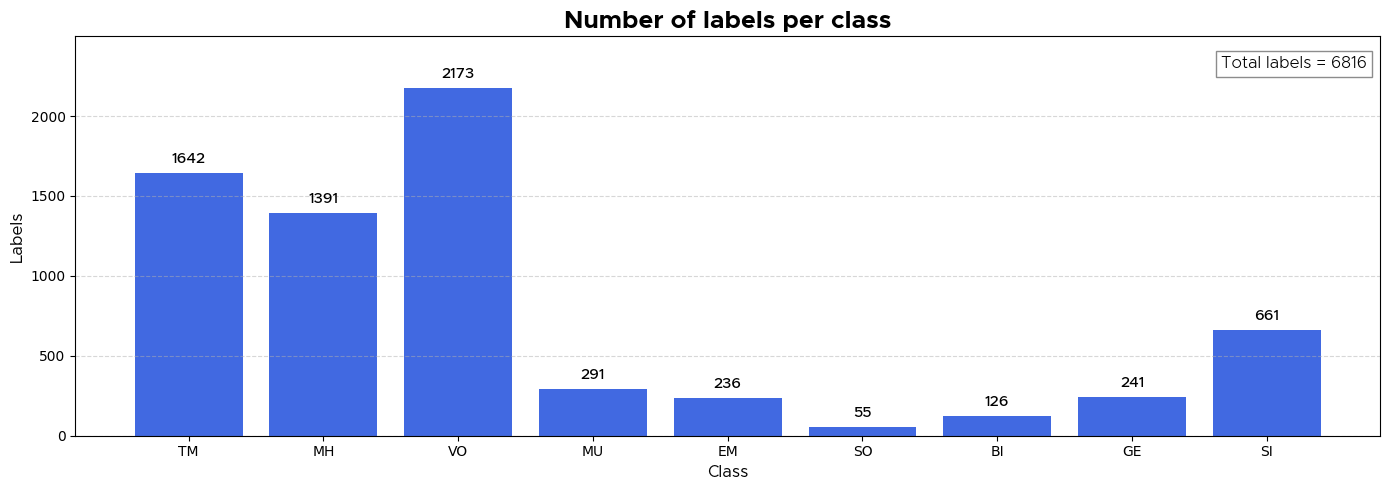

In [7]:
# how many labels we have

# this time, we count every label inside of the multi-hot vector associated with audio segments. So that, we expect
# to have more label than the audio segments we have: 5.130

labels_counts = ol[CLASS_NAMES].sum(axis=0).values.astype(int)

counts_ol = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Count": labels_counts
})

plt.figure(figsize=(14, 5))
bars = plt.bar(counts_ol["Class"], counts_ol["Count"], color="royalblue")
plt.ylim(0, counts_ol["Count"].max() * 1.15)
plt.title(
    "Number of labels per class",
    fontproperties=metro["bold"],
    fontsize=18
)

plt.xlabel("Class", fontproperties=metro["regular"], fontsize=12)
plt.ylabel("Labels", fontproperties=metro["regular"], fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        altura + (counts_ol["Count"].max() * 0.02),
        str(int(altura)),
        ha="center",
        va="bottom",
        fontproperties=metro["medium"],
        fontsize=11
    )

total_labels = counts_ol["Count"].sum()

plt.text(
    0.99, 0.95,
    f"Total labels = {total_labels}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontproperties=metro["light"],
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="gray", alpha=0.9)
)

plt.tight_layout()
plt.show()

In [8]:
ol["original_idx"] = ol.index # unique identifier for each label
ol.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx
185,004_40_P2.wav,0,0,0,0,0,0,0,0,1,185
4418,090_70_P1.wav,0,1,1,0,0,0,0,0,0,4418
2556,055_43_P2.wav,0,0,1,1,0,0,0,0,0,2556
2122,044_39_P2.wav,0,0,0,0,0,0,0,0,1,2122
1270,026_60_P2.wav,0,0,0,0,0,0,1,0,0,1270


### Functions

In [9]:
# function to extract points

def extract_point(fname):
    return re.search(r"(\d{3})_", fname).group(1)

# function to extract periods

def extract_period(fname):
    return "P1" if "_P1" in fname else "P2"

In [10]:
# function to select labels

def select_stratified(subset, N, seed=42): 
    """
    this function select labels for training, vallidation and test splits
    "N" is the number of labels to select within the "subset" of 27 labels in each point and period given. 
    "N" changes according with each split. For instance N = 5 for training.
    """
    
    chosen_segments = []
    used_original_idx = set()

    # force rare classes inclusion when possible
    for cls in R_CLASSES_NAMES:
        rare_subset = subset[subset[cls] == 1] # detect  rare clases if they are 1 = present 

        # avoid to use labels already selected as one instance could have mor than one label 
        rare_subset = rare_subset[
            ~rare_subset["original_idx"].isin(used_original_idx)
        ]

        if len(rare_subset) > 0:

            # select two labels for SO and just one for the rest of rare classes
            
            if cls == "SO":
                n_force = min(2, len(rare_subset))
            else:
                n_force = 1

            rows = rare_subset.sample(
                n=n_force,
                random_state=seed
            )

            chosen_segments.append(rows)
            used_original_idx.update(rows["original_idx"].tolist())

    # to achieve N the rest of labels are taken randomly 
    if len(chosen_segments) > 0:
        forced = pd.concat(chosen_segments)

        # avoid duplicate here again
        forced = forced.drop_duplicates(subset="original_idx")

        remaining = subset.drop(forced.index)
        need = max(0, N - len(forced))

        if need > 0 and len(remaining) > 0:
            rand_fill = remaining.sample(
                n=min(need, len(remaining)),
                random_state=seed
            )

            final = pd.concat([forced, rand_fill])
        else:
            final = forced
    else:
        # if not rare classes does not exist we justa apply simple random selection
        final = subset.sample(
            n=min(N, len(subset)),
            random_state=seed
        )

    return final.drop_duplicates(subset="original_idx").head(N)

In [11]:
# functioin to filter labels to examine Mels per class

def filter_by_labels(ol, active_labels, CLASS_NAMES):
    """
    df: dataframe containing the labels
    active_labels: list of labels that must be 1
    CLASS_NAMES: list of ALL label columns
    """
    # Condition: active labels must be 1
    cond_active = (ol[active_labels] == 1).all(axis=1)

    # Condition: all other labels must be 0
    inactive_labels = [c for c in CLASS_NAMES if c not in active_labels]
    cond_inactive = (ol[inactive_labels] == 0).all(axis=1)

    return ol[cond_active & cond_inactive]

In [12]:
# function to display Mel spectrograms by class

def show_mels_grid(filtered_ol, mels_dir, CLASS_NAMES, cols=5):
    total = len(filtered_ol)
    rows = math.ceil(total / cols)

    # Dynamically adjust figure size
    # 4 units high per row, 4 units wide per column
    fig_width = cols * 4
    fig_height = rows * 4

    fig, axes = plt.subplots(rows, cols, figsize=(fig_width, fig_height))
    axes = axes.flatten()

    # Disable all axes initially
    for ax in axes:
        ax.axis("off")

    for idx, (_, row) in enumerate(filtered_ol.iterrows()):
        fname = row["filename"]
        mel_path = os.path.join(mels_dir, fname.replace(".wav", ".png"))

        if os.path.exists(mel_path):
            img = Image.open(mel_path)
            axes[idx].imshow(img)
            labels = row[CLASS_NAMES].values
            axes[idx].set_title(f"{fname}\n{labels}", fontsize=10)
            axes[idx].axis("off")
        else:
            axes[idx].set_title("Does not exist", fontsize=10)

    # Adjust layout to remove white spaces
    plt.subplots_adjust(
        left=0, right=1, top=1, bottom=0,
        wspace=0.05, hspace=0.25
    )

    plt.show()

# 1. Select labels for train/val/test

We performed a division of the original labels to obtain balanced training, validation, and testing label sets by class (each class received its three train/val/test sets according to the available data), as well as balanced by sampling point and period to ensure a diverse spatiotemporal representation.

In [13]:
# add correponding points and periods colums to conform subsets

ol["point"]  = ol["filename"].apply(extract_point)
ol["period"] = ol["filename"].apply(extract_period)

ol.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx,point,period
1657,033_74_P2.wav,1,1,0,0,0,0,0,0,0,1657,033,P2
1582,032_38_P2.wav,1,1,1,0,0,0,0,0,0,1582,032,P2
4361,089_62_P1.wav,0,0,0,0,0,0,0,0,1,4361,089,P1
1127,024_04_P1.wav,1,0,0,0,0,0,0,0,0,1127,024,P1
10,001_18_P1.wav,1,0,1,0,0,0,0,0,0,10,001,P1


In [14]:
points = sorted(ol["point"].unique())   # 95 real points. We sampled 106 during day and 102 during night, but just preserved those 95 that geographical matched.
len(points)

95

In [15]:
# set up the number of labels to achieve within each subset
# we do not define a number for training, as it would be the remainder from validation and test label selection.

N_val  = 5
N_test = 2

In [16]:
# select labels for validation and test

val_rows  = []
test_rows = []

for p in points:
    for period in ["P1", "P2"]:

        segments_points = ol[(ol["point"] == p) &
                         (ol["period"] == period)]

        # validation labels
        val_sel = select_stratified(segments_points, N_val, seed=42)
        val_rows.append(val_sel)

        # test labels
        remaining = segments_points.drop(val_sel.index)
        test_sel = select_stratified(remaining, N_test, seed=123)
        test_rows.append(test_sel)


In [17]:
# finally build train_df, val_df and test_df

val_df  = pd.concat(val_rows).drop_duplicates(subset="original_idx")
test_df = pd.concat(test_rows).drop_duplicates(subset="original_idx")

used_idx = set(val_df["original_idx"]) | set(test_df["original_idx"])
train_df = ol[~ol["original_idx"].isin(used_idx)] # 20 labels remained per point in each period

In [18]:
train_df
#75% aprox. of total audio segments

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx,point,period
2,001_05_P2.wav,1,0,0,0,0,0,0,0,0,2,001,P2
3,001_06_P1.wav,1,0,0,0,0,0,0,0,0,3,001,P1
4,001_09_P1.wav,1,0,0,0,0,0,0,0,0,4,001,P1
5,001_10_P2.wav,1,0,0,0,0,0,0,0,0,5,001,P2
6,001_11_P1.wav,1,0,0,0,0,0,0,0,0,6,001,P1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5109,073_09_P2.wav,0,0,0,0,0,0,0,0,1,5109,073,P2
5110,073_12_P2.wav,0,0,0,0,0,0,0,0,1,5110,073,P2
5111,073_14_P1.wav,0,0,0,0,1,0,0,0,0,5111,073,P1
5112,073_15_P2.wav,0,0,0,0,0,0,0,0,1,5112,073,P2


In [19]:
val_df
#18% aprox. of total audio segments

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx,point,period
16,001_29_P1.wav,1,0,0,0,0,0,0,0,0,16,001,P1
27,001_46_P1.wav,1,0,0,0,0,0,0,0,0,27,001,P1
18,001_33_P1.wav,1,0,0,0,0,0,0,0,0,18,001,P1
43,001_73_P1.wav,1,0,0,0,0,0,0,0,0,43,001,P1
0,001_04_P1.wav,1,0,0,0,0,0,0,0,0,0,001,P1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5074,102_83_P2.wav,1,0,1,0,1,0,0,0,0,5074,102,P2
5029,102_08_P2.wav,0,0,1,0,0,0,0,1,0,5029,102,P2
5043,102_32_P2.wav,0,1,1,0,0,0,0,0,0,5043,102,P2
5060,102_60_P2.wav,0,1,1,0,0,0,0,0,0,5060,102,P2


In [20]:
test_df
#8% aprox. of total audio segments

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx,point,period
10,001_18_P1.wav,1,0,1,0,0,0,0,0,0,10,001,P1
21,001_35_P1.wav,1,0,0,0,0,0,0,0,0,21,001,P1
11,001_20_P2.wav,1,1,0,0,0,0,0,0,0,11,001,P2
20,001_34_P2.wav,0,1,0,0,0,0,0,0,0,20,001,P2
65,002_20_P1.wav,1,0,1,0,0,0,0,0,0,65,002,P1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4981,101_19_P2.wav,0,1,1,0,0,0,0,0,0,4981,101,P2
5035,102_20_P1.wav,0,1,1,0,0,0,0,0,0,5035,102,P1
5045,102_34_P1.wav,0,1,1,0,0,0,0,0,0,5045,102,P1
5065,102_69_P2.wav,1,0,1,0,1,0,0,0,0,5065,102,P2


### Class distribution verification

In [21]:
# add 'split' to concatanate according each split

train_df["split"] = "train"
val_df["split"]   = "val"
test_df["split"]  = "test"

print("train_df:")
print(list(train_df.columns), "\n")

print("val_df:")
print(list(val_df.columns), "\n")

print("test_df:")
print(list(test_df.columns), "\n")

train_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI', 'original_idx', 'point', 'period', 'split'] 

val_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI', 'original_idx', 'point', 'period', 'split'] 

test_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI', 'original_idx', 'point', 'period', 'split'] 



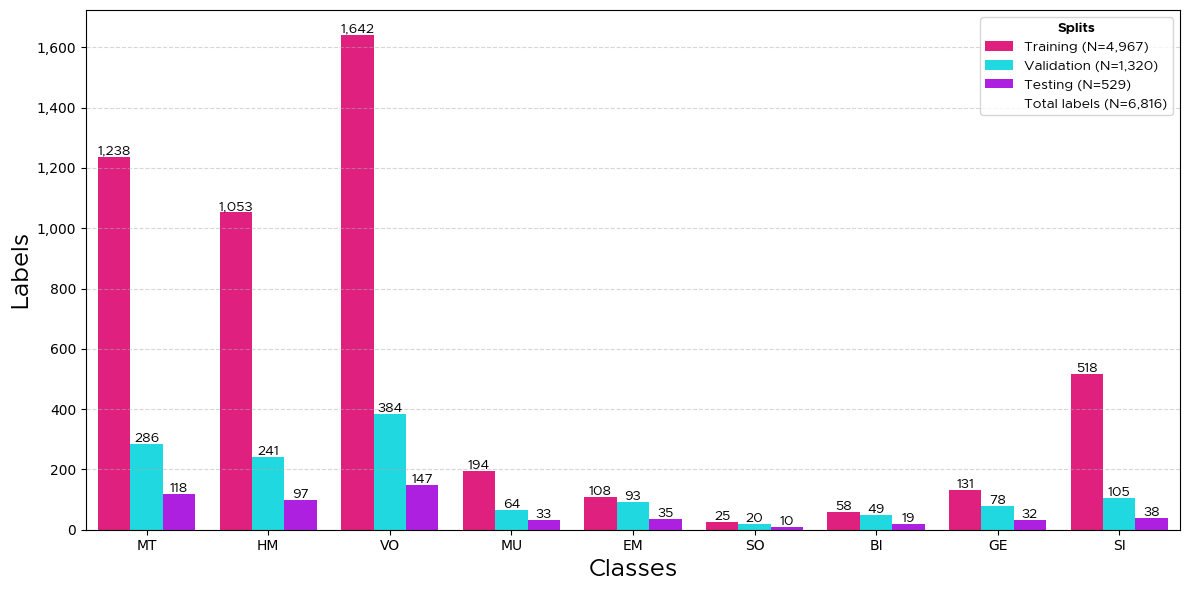

In [22]:
# how looks like our class numbers per split

# join all splits
full = pd.concat([train_df, val_df, test_df], ignore_index=True)
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

# count segments per class and split
count_data = full.melt(
    id_vars="split",
    value_vars=CLASS_NAMES,
    var_name="Class",
    value_name="Present"
)

count_data = count_data[count_data["Present"] == 1]

# rename class labels for the plot
class_names_plot = {
    "TM": "MT",
    "MH": "HM"
}

count_data["Class"] = count_data["Class"].replace(class_names_plot)

sns.countplot(
    data=count_data,
    x="Class",
    hue="split",
    ax=ax,
    palette=["#ff007f", "#00f6ff", "#bd00ff"]
)

# axis
ax.set_xlabel("Classes", fontproperties=metro["regular"], fontsize=18)
ax.set_ylabel("Labels", fontproperties=metro["regular"], fontsize=18)

ax.grid(axis="y", linestyle="--", alpha=0.5)

# labels number count above bars
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:,.0f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontproperties=metro["regular"]
        )

# labels number count per split in legend
partition_totals = (
    count_data
    .groupby("split")
    .size()
    .to_dict()
)

total_global = sum(partition_totals.values())

# total labels count in legend
handles, labels = ax.get_legend_handles_labels()

split_names = {
    "train": "Training",
    "val": "Validation",
    "test": "Testing"
}

new_labels = [
    f"{split_names.get(label, label)} (N={partition_totals.get(label, 0):,})"
    for label in labels
]

handles.append(Line2D([0], [0], color="none"))
new_labels.append(f"Total labels (N={total_global:,})")

ax.legend(
    handles,
    new_labels,
    title="Splits",
    frameon=True,
    prop=metro["regular"],
    title_fontproperties=metro["bold"]
)

# format y-axis numbers with English thousands separators
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

plt.tight_layout()
plt.show()

# We seek a division of labels for training, validation, and testing that is proportional to each class, including both
# non-rare and rare classes in our data.

In [23]:
# save plot

out_dir = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\plots"

fig.savefig(
    os.path.join(out_dir, "Figure 7.png"),
    dpi=300,
    bbox_inches="tight"
)

### Spatiotemporal distribution verification

Since the balance of the splits was not only by class but also by sampling point and period, we expect to have an equal proportion of training, validation, and testing labels for each sampled point and period.

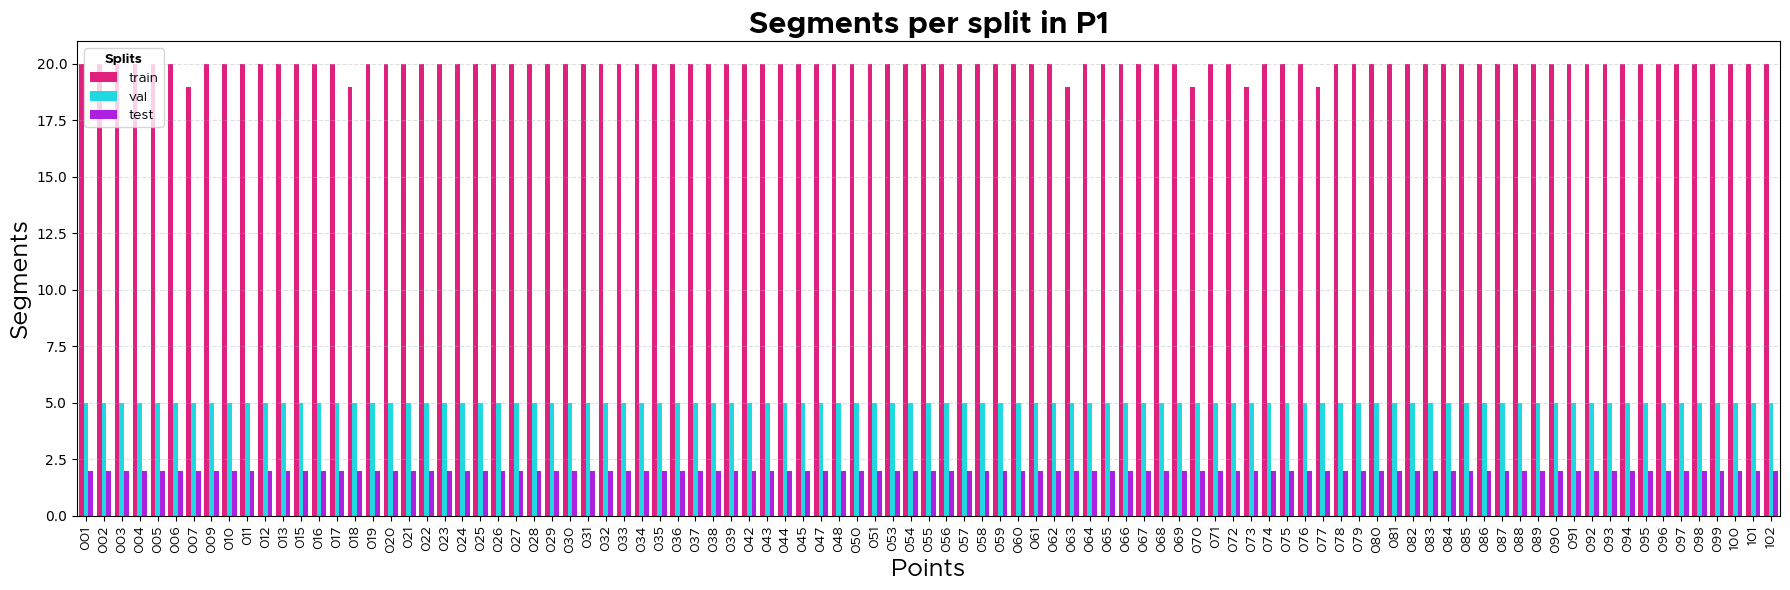

In [22]:
# filter by period P1
 
p1 = full[full["period"] == "P1"]

plt.figure(figsize=(18,6))
sns.countplot(data=p1, x="point", hue="split", palette=["#ff007f", "#00f6ff", "#bd00ff"]
)
plt.xticks(rotation=90, fontproperties=metro["regular"], fontsize=10)
plt.xlabel("Points", fontproperties=metro["regular"], fontsize=18)
plt.ylabel("Segments", fontproperties=metro["regular"], fontsize=18)

plt.title("Segments per split in P1",
          fontproperties=metro["bold"], fontsize=22)

plt.grid(axis="y", linestyle="--", alpha=0.4)

leg = plt.legend(title="Splits", title_fontproperties=metro["bold"], prop=metro["regular"])

plt.tight_layout()
plt.show()

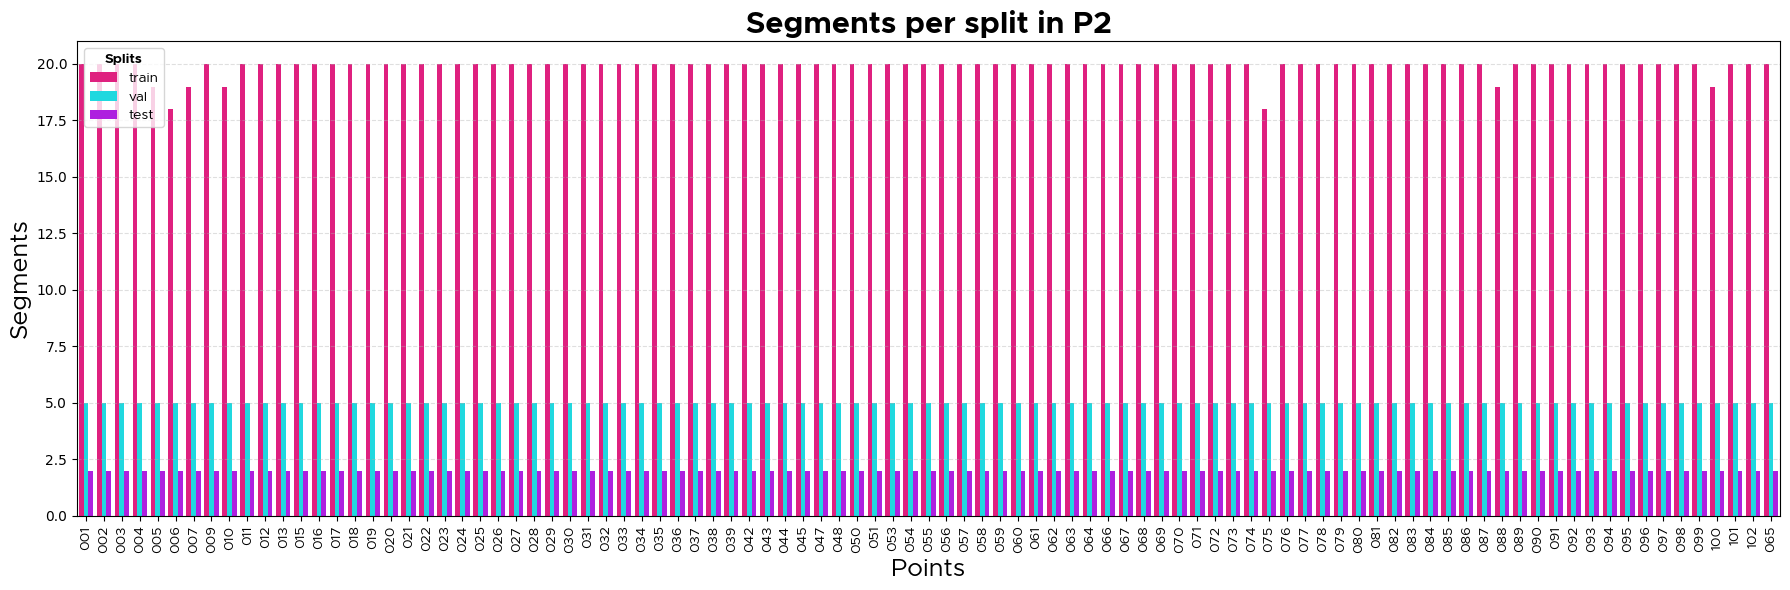

In [23]:
# filter by period P2
 
p1 = full[full["period"] == "P2"]

plt.figure(figsize=(18,6))
sns.countplot(data=p1, x="point", hue="split", palette=["#ff007f", "#00f6ff", "#bd00ff"])
plt.xticks(rotation=90, fontproperties=metro["regular"], fontsize=10)
plt.xlabel("Points", fontproperties=metro["regular"], fontsize=18)
plt.ylabel("Segments", fontproperties=metro["regular"], fontsize=18)

plt.title("Segments per split in P2",
          fontproperties=metro["bold"], fontsize=22)

plt.grid(axis="y", linestyle="--", alpha=0.4)

leg = plt.legend(title="Splits", title_fontproperties=metro["bold"], prop=metro["regular"])

plt.tight_layout()
plt.show()

In [24]:
# RARE CLASSES

for cls in R_CLASSES_NAMES:
    total_cls = int((full[cls] == 1).sum())
    train_cls = int((train_df[cls] == 1).sum())
    val_cls   = int((val_df[cls]   == 1).sum())
    test_cls  = int((test_df[cls]  == 1).sum())

    print(f"{cls} → Total:{total_cls} | Train:{train_cls} | Val:{val_cls} | Test:{test_cls}")

MU → Total:291 | Train:194 | Val:64 | Test:33
EM → Total:236 | Train:108 | Val:93 | Test:35
SO → Total:55 | Train:25 | Val:20 | Test:10
BI → Total:126 | Train:58 | Val:49 | Test:19
GE → Total:241 | Train:131 | Val:78 | Test:32


In [25]:
# NORMAL CLASSES

not_rare = ["TM", "MH", "VO", "SI"]

for cls in not_rare:
    total_cls = int((full[cls] == 1).sum())
    train_cls = int((train_df[cls] == 1).sum())
    val_cls   = int((val_df[cls]   == 1).sum())
    test_cls  = int((test_df[cls]  == 1).sum())

    print(f"{cls} → Total:{total_cls} | Train:{train_cls} | Val:{val_cls} | Test:{test_cls}")


TM → Total:1642 | Train:1238 | Val:286 | Test:118
MH → Total:1391 | Train:1053 | Val:241 | Test:97
VO → Total:2173 | Train:1642 | Val:384 | Test:147
SI → Total:661 | Train:518 | Val:105 | Test:38


### Cleaning

In [26]:
# CLEAN AUXILIAR COLUMS

aux_cols = ["original_idx", "point", "period", "split"]

train_df = train_df.drop(columns=aux_cols).reset_index(drop=True)
val_df   = val_df.drop(columns=aux_cols).reset_index(drop=True)
test_df  = test_df.drop(columns=aux_cols).reset_index(drop=True)

print("train_df:")
print(list(train_df.columns), "\n")

print("val_df:")
print(list(val_df.columns), "\n")

print("test_df:")
print(list(test_df.columns), "\n")

train_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI'] 

val_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI'] 

test_df:
['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI'] 



In [27]:
# Verify
train_df.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
1176,032_58_P1.wav,0,1,1,0,0,0,0,0,0
32,001_77_P1.wav,1,0,0,0,0,0,0,0,0
3551,097_76_P1.wav,0,1,1,0,0,0,0,0,0
1399,038_17_P2.wav,0,0,1,0,0,0,0,0,0
2064,059_73_P2.wav,0,0,0,1,0,0,0,0,0


In [28]:
# Verify
val_df.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
331,036_29_P1.wav,1,1,1,0,0,0,0,0,0
236,026_43_P2.wav,0,0,0,0,0,0,0,1,0
361,039_46_P1.wav,0,1,1,0,0,0,0,0,0
56,006_50_P2.wav,1,0,0,0,0,0,0,1,0
573,065_55_P1.wav,1,0,0,0,0,0,0,0,0


In [29]:
# Drop column EM
test_df.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
291,080_45_P2.wav,1,0,0,0,0,0,1,1,0
230,065_70_P2.wav,1,0,0,0,0,0,0,1,0
241,068_37_P1.wav,0,1,1,0,0,0,0,0,0
131,035_35_P2.wav,0,0,0,0,0,0,0,0,1
138,037_19_P2.wav,0,1,1,0,0,0,0,0,0


### Saving

In [30]:
# SAVE SPLITS (without EM column)

train_df.to_csv(
    r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_pb.csv",
    index=False,
    encoding="utf-8"
)

val_df.to_csv(
    r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\val_df_pb.csv",
    index=False,
    encoding="utf-8"
)

test_df.to_csv(
    r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_df_pb.csv",
    index=False,
    encoding="utf-8"
)

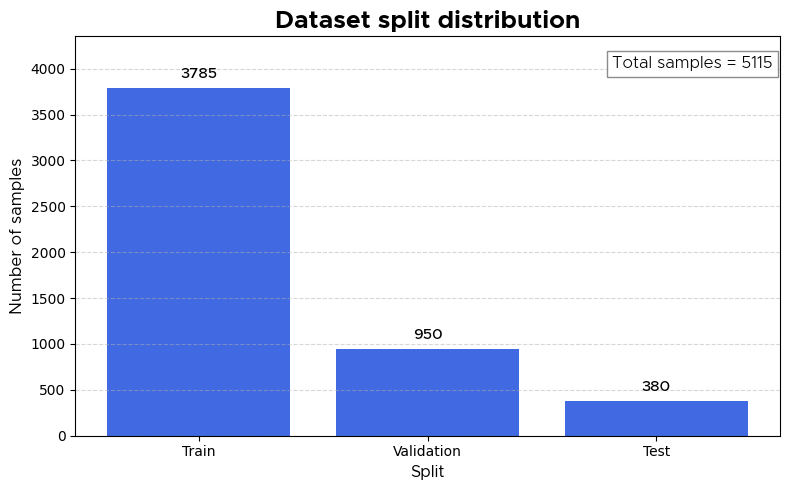

In [31]:
# Dataset split counts plot

counts = {
    "Train": len(train_df),
    "Validation": len(val_df),
    "Test": len(test_df)
}

splits = list(counts.keys())
values = list(counts.values())
total = sum(values)

plt.figure(figsize=(8, 5))
bars = plt.bar(splits, values, color="royalblue")
plt.ylim(0, max(values) * 1.15)

plt.title(
    "Dataset split distribution",
    fontproperties=metro["bold"],
    fontsize=18
)

plt.xlabel("Split", fontproperties=metro["regular"], fontsize=12)
plt.ylabel("Number of samples", fontproperties=metro["regular"], fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)

# Value on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + (max(values) * 0.02),
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontproperties=metro["medium"],
        fontsize=11
    )

# Total annotation
plt.text(
    0.99, 0.95,
    f"Total samples = {total}",
    transform=plt.gca().transAxes,
    ha="right",
    va="top",
    fontproperties=metro["light"],
    fontsize=12,
    bbox=dict(facecolor="white", edgecolor="gray", alpha=0.9)
)

plt.tight_layout()
plt.show()

# 2. Inspect Mels per unique class 

We used this inspection to ensure that the Mels without overlapping classes were the best possible visual representation of each class according to the available data.

In [12]:
# functioin to filter labels to examine Mels per class

def filter_by_labels(ol, active_labels, CLASS_NAMES):
    """
    df: dataframe containing the labels
    active_labels: list of labels that must be 1
    CLASS_NAMES: list of ALL label columns
    """
    # Condition: active labels must be 1
    cond_active = (ol[active_labels] == 1).all(axis=1)

    # Condition: all other labels must be 0
    inactive_labels = [c for c in CLASS_NAMES if c not in active_labels]
    cond_inactive = (ol[inactive_labels] == 0).all(axis=1)

    return ol[cond_active & cond_inactive]

In [13]:
def filter_by_label_any(df, label):
    """
    Filters rows where `label == 1`,
    regardless of other labels.
    """
    return df[df[label] == 1]

In [24]:
ol_c_any = filter_by_label_any(ol, "MU")

print("Number of Mels with BI=1:", len(ol_c_any))
ol_c_any.head()

Number of Mels with BI=1: 291


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx
969,021_09_P1.wav,0,0,1,1,0,0,0,0,0,969
972,021_14_P1.wav,0,1,0,1,0,0,0,0,0,972
973,021_16_P1.wav,0,1,1,1,0,0,0,0,0,973
975,021_19_P1.wav,0,1,1,1,0,0,0,0,0,975
979,021_26_P1.wav,0,1,0,1,0,0,0,0,0,979


In [23]:
# FILTER CLASS

ol_c_only = filter_by_labels(
    ol=ol,
    active_labels=["MU"],          # change to inspect any label: TM, MH, VO, MU, EM, SO, BI, GE, SI
    CLASS_NAMES=CLASS_NAMES
)

print("Number of Mels with only BI=1:", len(ol_c_only))
ol_c_only.head()

Number of Mels with only BI=1: 140


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,original_idx
1185,025_09_P2.wav,0,0,0,1,0,0,0,0,0,1185
1233,025_87_P2.wav,0,0,0,1,0,0,0,0,0,1233
1830,037_03_P1.wav,0,0,0,1,0,0,0,0,0,1830
1831,037_05_P1.wav,0,0,0,1,0,0,0,0,0,1831
1845,037_28_P1.wav,0,0,0,1,0,0,0,0,0,1845


In [16]:
def labels_to_combination(row, CLASS_NAMES, sep="+"):
    """
    Converts a binary label vector into a categorical combination string.
    Example: [0,1,0,0,0,1,0,0,0] -> 'MH+SO'
    """
    active = [cls for cls in CLASS_NAMES if row[cls] == 1]
    return sep.join(active) if active else "NONE"

In [17]:
def show_mels_grid(
    filtered_ol,
    mels_dir,
    CLASS_NAMES,
    cols=5,
    fname_fontsize=9,
    combo_fontsize=12,
    vector_fontsize=8,
):
    total = len(filtered_ol)
    rows = math.ceil(total / cols)

    # Dynamic figure size
    fig_width = cols * 4
    fig_height = rows * 4

    fig, axes = plt.subplots(rows, cols, figsize=(fig_width, fig_height))
    axes = axes.flatten()

    # Disable all axes initially
    for ax in axes:
        ax.axis("off")

    for idx, (_, row) in enumerate(filtered_ol.iterrows()):
        fname = row["filename"]
        mel_path = os.path.join(mels_dir, fname.replace(".wav", ".png"))

        if os.path.exists(mel_path):
            img = Image.open(mel_path)
            axes[idx].imshow(img)

            # --- labels ---
            labels_vec = row[CLASS_NAMES].values.tolist()
            combo = labels_to_combination(row, CLASS_NAMES)

            # Title text (multi-line)
            title = (
                f"{fname}\n"
                rf"$\mathbf{{{combo}}}$"  # bold categorical combination
                f"\n{labels_vec}"
            )

            axes[idx].set_title(
                title,
                fontsize=fname_fontsize,
                pad=6,
            )

            axes[idx].axis("off")
        else:
            axes[idx].set_title("Does not exist", fontsize=fname_fontsize)

    plt.subplots_adjust(
        left=0, right=1, top=1, bottom=0,
        wspace=0.05, hspace=0.35
    )

    plt.show()

In [ ]:
show_mels_grid(ol_c_only, ORG_MELS_DIR, CLASS_NAMES)

# SO: Social communal sounds in cities are frequently produced by church bells or sirens from
# emergency services. They often appear as pyramidal and horizontal lines in Mels.

In [ ]:
show_mels_grid(ol_c_any, ORG_MELS_DIR, CLASS_NAMES)


In [42]:
def row_to_combination(row, CLASS_NAMES, sep="+"):
    active = [c for c in CLASS_NAMES if row[c] == 1]
    return sep.join(active) if active else "NONE"

In [43]:
import pandas as pd

def compute_combination_frequencies(df, CLASS_NAMES, anchor_class=None):
    """
    Computes frequency of active label combinations.
    
    anchor_class: str or None
        If provided, only rows where anchor_class == 1 are considered.
    """

    if anchor_class is not None:
        df = df[df[anchor_class] == 1]

    combos = df.apply(
        lambda row: row_to_combination(row, CLASS_NAMES),
        axis=1
    )

    freq = (
        combos
        .value_counts()
        .reset_index()
        .rename(columns={"index": "combination", 0: "count"})
    )

    return freq

In [44]:
import matplotlib.pyplot as plt

def plot_combination_frequencies(
    freq_df,
    title="Frequency of label combinations",
    figsize=(10, 6),
    font_size=11
):
    plt.figure(figsize=figsize)

    plt.barh(
        freq_df["combination"],
        freq_df["count"]
    )

    plt.xlabel("Frequency", fontsize=font_size)
    plt.ylabel("Label combination", fontsize=font_size)
    plt.title(title, fontsize=font_size + 2)

    plt.gca().invert_yaxis()  # most frequent on top
    plt.tight_layout()
    plt.show()

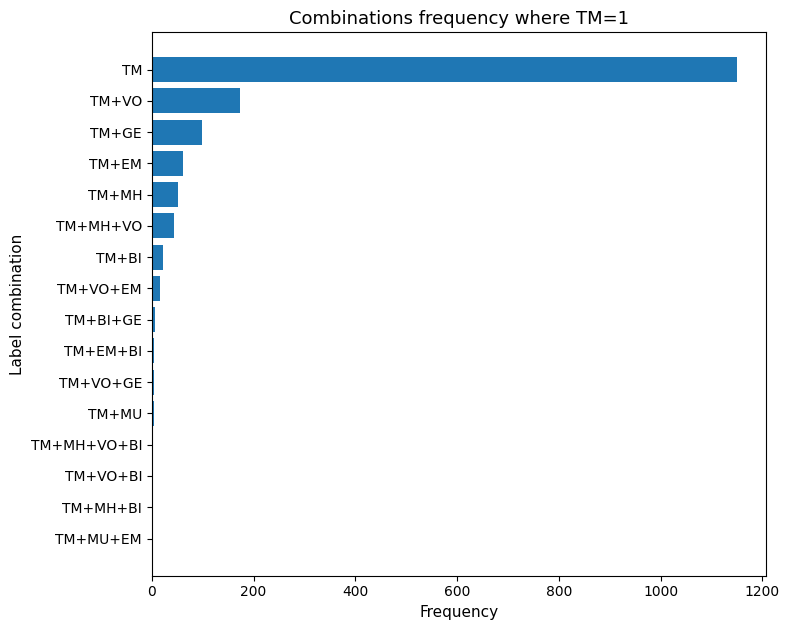

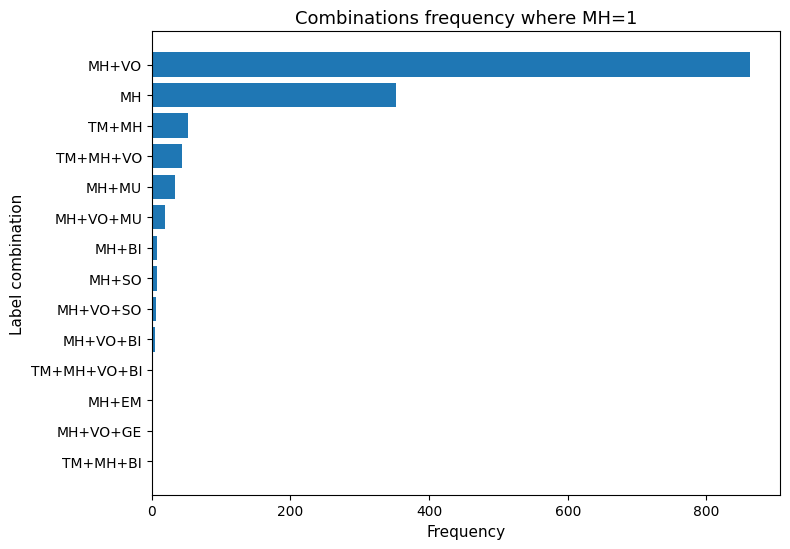

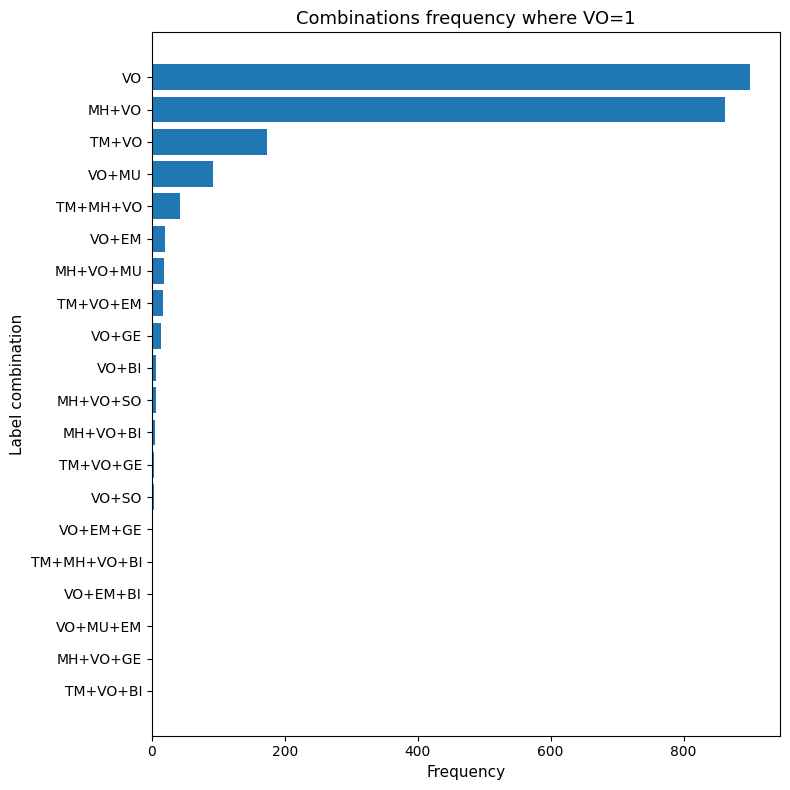

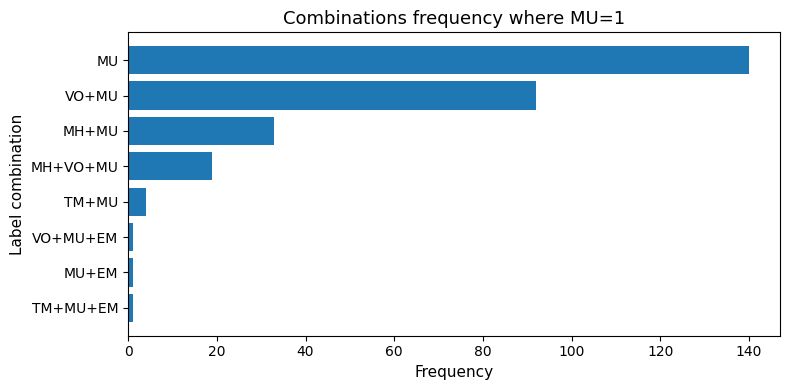

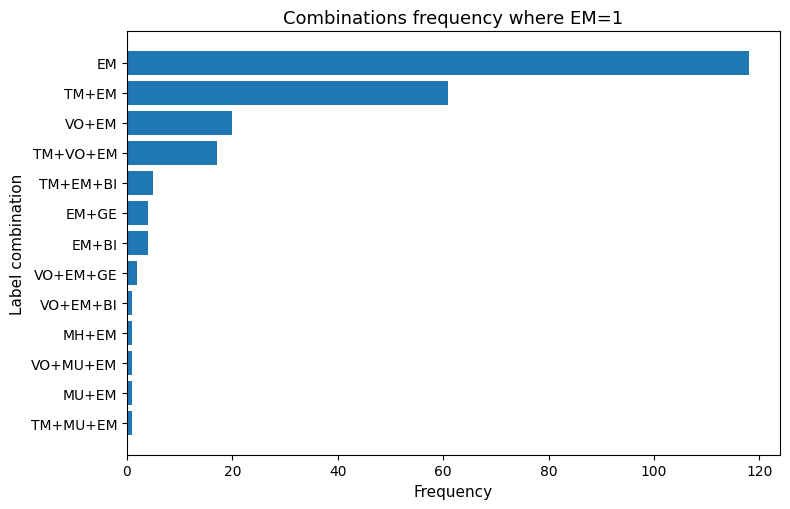

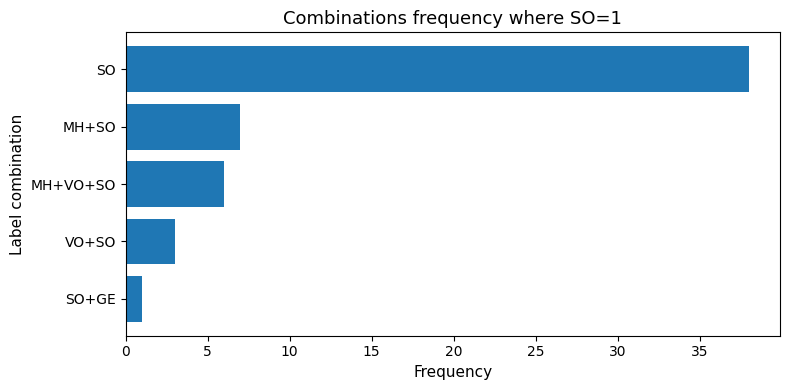

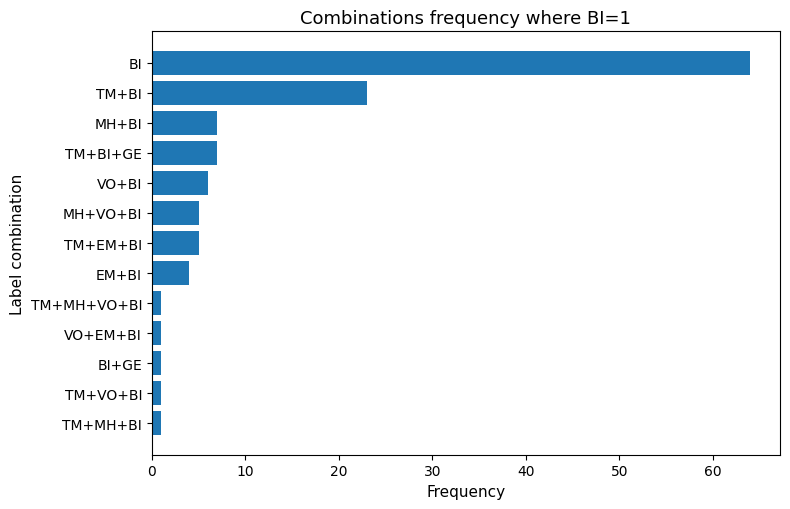

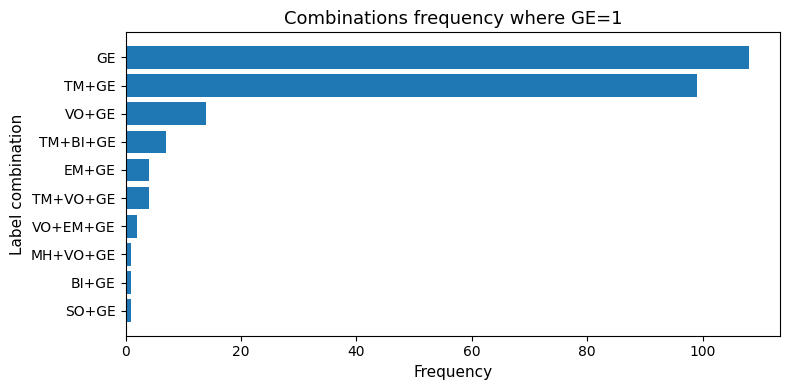

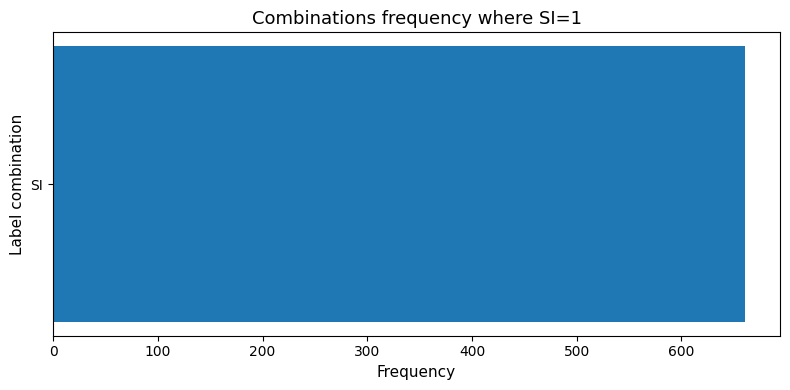

In [45]:
for cls in ["TM", "MH", "VO", "MU", "EM", "SO", "BI", "GE", "SI"]:
    freq = compute_combination_frequencies(
        ol,
        CLASS_NAMES,
        anchor_class=cls
    )
    plot_combination_frequencies(
        freq,
        title=f"Combinations frequency where {cls}=1",
        figsize=(8, max(4, len(freq) * 0.4))
    )